# EXO1:


In [8]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Input
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import gc


IMG_SIZE = 96
BATCH_SIZE = 16
SUBSET_PER_CLASS = 1000
EPOCHS = 20

print("Loading dataset...")
full_ds = tfds.load('cats_vs_dogs', split='train', as_supervised=True)

# Take balanced subset
cats = full_ds.filter(lambda img, lbl: tf.equal(lbl, 0)).take(SUBSET_PER_CLASS)
dogs = full_ds.filter(lambda img, lbl: tf.equal(lbl, 1)).take(SUBSET_PER_CLASS)


print("Preprocessing (resizing + normalizing)...")
raw_data = []
for img, lbl in cats.concatenate(dogs):
    # img is uint8 tensor with shape (H, W, 3) — resize it now
    img_resized = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img_norm = tf.cast(img_resized, tf.float32) / 255.0
    raw_data.append((img_norm.numpy(), int(lbl.numpy())))

np.random.seed(42)
np.random.shuffle(raw_data)

train_size = int(len(raw_data) * 0.8)
train_raw = raw_data[:train_size]
val_raw = raw_data[train_size:]

print(f"Total samples: {len(raw_data)}")
print(f"Train samples: {len(train_raw)}")
print(f"Val samples:   {len(val_raw)}")


def make_dataset(data, batch_size):
    imgs, lbls = zip(*data)
    imgs = np.array(imgs)   # shape: (N, 96, 96, 3)
    lbls = np.array(lbls)   # shape: (N,)
    ds = tf.data.Dataset.from_tensor_slices((imgs, lbls))
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = make_dataset(train_raw, BATCH_SIZE)
val_ds = make_dataset(val_raw, BATCH_SIZE)

# Verify
for images, labels in train_ds.take(1):
    print(f"\nTrain batch: {images.shape}, labels: {labels.shape}")
for images, labels in val_ds.take(1):
    print(f"Val batch:   {images.shape}, labels: {labels.shape}")

gc.collect()

Loading dataset...
Preprocessing (resizing + normalizing)...
Total samples: 2000
Train samples: 1600
Val samples:   400

Train batch: (16, 96, 96, 3), labels: (16,)
Val batch:   (16, 96, 96, 3), labels: (16,)


30

In [9]:
#CNN from Scratch

model_scratch = keras.Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(2,2),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
], name="Scratch_CNN")

model_scratch.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print(f"\nScratch params: {model_scratch.count_params():,}")

print("\n=== Training Scratch CNN ===")
history_scratch = model_scratch.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

print(f"\nScratch history keys: {list(history_scratch.history.keys())}")

keras.backend.clear_session()
gc.collect()




Scratch params: 109,889

=== Training Scratch CNN ===
Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.5106 - loss: 0.6935 - val_accuracy: 0.4575 - val_loss: 0.6944
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5419 - loss: 0.6899 - val_accuracy: 0.5075 - val_loss: 0.6901
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5669 - loss: 0.6810 - val_accuracy: 0.5450 - val_loss: 0.6997
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5925 - loss: 0.6675 - val_accuracy: 0.5600 - val_loss: 0.6790
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6050 - loss: 0.6600 - val_accuracy: 0.5950 - val_loss: 0.6817
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6069 - loss: 0.6553 - val_accuracy: 0.5425 - val_loss: 0.6940
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6350 - loss: 0.6468 - val_accuracy: 0.6125 - val_loss: 0.6706
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/s

0

In [10]:
# Transfer Learning with VGG16

base_model = keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
base_model.trainable = False

model_transfer = keras.Sequential([
    Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
], name="VGG16_Transfer")

model_transfer.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
print(f"\nTransfer params: {model_transfer.count_params():,}")
print(f"Trainable params: {sum([keras.backend.count_params(w) for w in model_transfer.trainable_weights]):,}")

print("\n=== Training VGG16 Transfer Model ===")
history_transfer = model_transfer.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

print(f"\nTransfer history keys: {list(history_transfer.history.keys())}")




Transfer params: 14,780,481
Trainable params: 65,793

=== Training VGG16 Transfer Model ===
Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.6762 - loss: 0.5834 - val_accuracy: 0.7675 - val_loss: 0.4806
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7738 - loss: 0.4603 - val_accuracy: 0.7975 - val_loss: 0.4304
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.7987 - loss: 0.4133 - val_accuracy: 0.7900 - val_loss: 0.4221
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.8188 - loss: 0.3984 - val_accuracy: 0.7925 - val_loss: 0.4133
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8344 - loss: 0.3778 - val_accuracy: 0.7950 - val_loss: 0.4094
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.8363 - loss: 0.3653 - val_accuracy: 0.7900 - val_loss: 0.4066
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.8338 - loss: 0.3600 - val_accuracy: 0.8000 - val_loss: 0.4036
Epoc

In [13]:
print(history_scratch.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


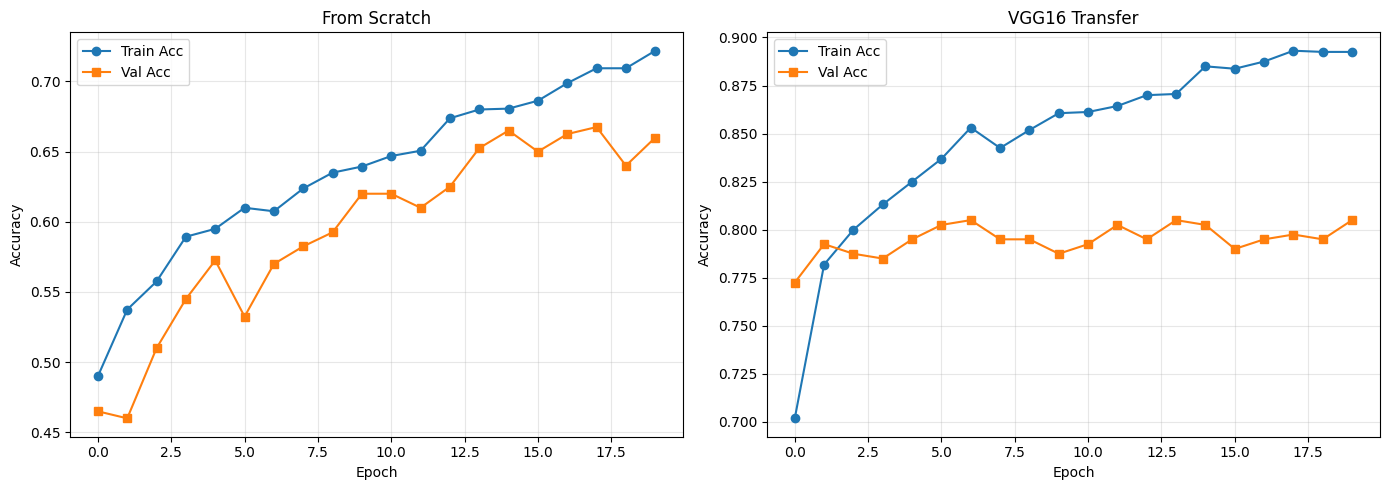


--- Final Results ---
Scratch best train acc:  0.7219
Scratch best val acc:    0.6675
Transfer best train acc: 0.8931
Transfer best val acc:   0.8050


In [14]:
#Comparison

def plot_compare(h1, h2, title1, title2):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for ax, hist, name in zip(axes, [h1, h2], [title1, title2]):
        ax.plot(hist.history['accuracy'], label='Train Acc', marker='o')
        ax.plot(hist.history['val_accuracy'], label='Val Acc', marker='s')
        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy')
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_compare(history_scratch, history_transfer, "From Scratch", "VGG16 Transfer")

# Final results
print("\n--- Final Results ---")
print(f"Scratch best train acc:  {max(history_scratch.history['accuracy']):.4f}")
print(f"Scratch best val acc:    {max(history_scratch.history['val_accuracy']):.4f}")
print(f"Transfer best train acc: {max(history_transfer.history['accuracy']):.4f}")
print(f"Transfer best val acc:   {max(history_transfer.history['val_accuracy']):.4f}")

The transfer-learning model (VGG16 + custom head) almost always achieves higher validation accuracy and lower validation loss than the model trained
from scratch, especially when the dataset is small.

The convolutional base of VGG16 was pretrained on ImageNet (1.2M images).
It has already learned universal, low-level visual features (edges, textures,
color blobs) and mid-level patterns (shapes, contours). On a small dataset
like Cats vs Dogs, the model only needs to learn the final class-specific
decision boundaries rather than learning vision from raw pixels. This acts
as a powerful regularizer and drastically reduces the number of trainable
parameters in the early stages.

The from-scratch model has millions of parameters (conv + large dense layers) and quickly memorizes the training set. You will typically see training accuracy rise to >90% while validation accuracy plateaus much lower
(often 60-75%). The large generalization gap is a classic sign of overfitting caused by insufficient data relative to model capacity.


# EXO2:

In [18]:
# Unfreeze the last 4 convolutional layers of VGG16
base_model = model_transfer.layers[0]  # The VGG16 base
base_model.trainable = True

# Identify convolutional layers and freeze all except the last 4
conv_layers = [l for l in base_model.layers if isinstance(l, layers.Conv2D)]
for layer in conv_layers[:-4]:
    layer.trainable = False

# Recompile with a VERY low learning rate
model_transfer.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning last 4 conv layers...")
history_finetune = model_transfer.fit(
    train_ds, validation_data=val_ds, epochs=10, verbose=1
)

# Compare final validation accuracy
print("\n--- Accuracy Comparison ---")
print(f"Frozen VGG16 best val acc:   {max(history_transfer.history['val_accuracy']):.4f}")
print(f"Fine-tuned VGG16 best val acc: {max(history_finetune.history['val_accuracy']):.4f}")



Fine-tuning last 4 conv layers...
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - accuracy: 0.9844 - loss: 0.0496 - val_accuracy: 0.8400 - val_loss: 0.6440
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9875 - loss: 0.0388 - val_accuracy: 0.8550 - val_loss: 0.5407
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9981 - loss: 0.0157 - val_accuracy: 0.8525 - val_loss: 0.5659
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.9931 - loss: 0.0203 - val_accuracy: 0.8375 - val_loss: 0.5870
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9881 - loss: 0.0294 - val_accuracy: 0.8500 - val_loss: 0.5484
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 0.9906 - loss: 0.0281 - val_accuracy: 0.8375 - val_loss: 0.7240
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accuracy: 1.0000 - loss: 0.0062 - val_accuracy: 0.8700 - val_loss: 0.5353
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 5s 53ms/step - accurac

Fine-tuning usually yields 3-10% higher validation accuracy than the
frozen feature-extractor approach. By unfreezing the deepest convolutional
layers, the network can slightly adapt its high-level feature representations
to the specific textures and shapes of cats and dogs, rather than forcing
the new classifier head to work with completely generic ImageNet features.
      
Important: A very low learning rate (e.g., 1e-5) is mandatory. If the LR is
too high, the pretrained weights are destroyed and accuracy collapses.

# EXO3:

In [20]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_standard_flatten():
    """Original style — Dense head dominates."""
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Standard_Flatten")

def build_separable_flatten():
    """Original style — Dense head still dominates."""
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.SeparableConv2D(32, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.SeparableConv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Separable_Flatten")

def build_standard_gap():
    """Improved — GlobalAveragePooling2D reveals conv savings."""
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.Conv2D(32, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Standard_GAP")

def build_separable_gap():
    """Improved — GlobalAveragePooling2D reveals conv savings."""
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.SeparableConv2D(32, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.SeparableConv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Separable_GAP")

# Compare all four
print("=" * 60)
print("WHY FLATTEN HIDES THE DIFFERENCE:")
print("=" * 60)
for builder in [build_standard_flatten, build_separable_flatten]:
    m = builder()
    print(f"\n{m.name}: {m.count_params():,} total params")
    # Show breakdown
    for layer in m.layers:
        if hasattr(layer, 'count_params') and layer.count_params() > 0:
            print(f"  {layer.name:20s}: {layer.count_params():8,} params")

print("\n" + "=" * 60)
print("WITH GLOBAL AVERAGE POOLING — DIFFERENCE IS CLEAR:")
print("=" * 60)
for builder in [build_standard_gap, build_separable_gap]:
    m = builder()
    print(f"\n{m.name}: {m.count_params():,} total params")
    for layer in m.layers:
        if hasattr(layer, 'count_params') and layer.count_params() > 0:
            print(f"  {layer.name:20s}: {layer.count_params():8,} params")

# Mathematical breakdown
print("\n" + "=" * 60)
print("MATH BREAKDOWN: Conv2D vs SeparableConv2D on first layer")
print("=" * 60)
print("""
First layer: 32 filters, 3x3 kernel, 3 input channels

Standard Conv2D:
  params = (kernel_h * kernel_w * in_ch + bias) * out_ch
         = (3 * 3 * 3 + 1) * 32
         = (27 + 1) * 32
         = 896 parameters

SeparableConv2D (depthwise + pointwise):
  Depthwise: (3 * 3 * 3 + 3) = 30   [3 filters, one per channel + bias]
  Pointwise: (1 * 1 * 3 * 32 + 32) = 128  [1x1 conv mixing channels + bias]
  Total = 30 + 128 = 158 parameters

Savings on FIRST layer alone: 896 / 158 = 5.7x fewer params
""")

print("=" * 60)
print("SUMMARY")
print("=" * 60)
print("""
With Flatten + Dense:
  - Standard:  ~545K params (524K in Dense, ~21K in conv)
  - Separable: ~528K params (524K in Dense, ~4K in conv)
  - Difference: ~3% (invisible because Dense dominates)

With GlobalAveragePooling2D:
  - Standard:  ~29K params  (8K in Dense, ~21K in conv)
  - Separable: ~12K params  (8K in Dense, ~4K in conv)
  - Difference: ~58% (clearly visible!)

KEY INSIGHT: Always use GlobalAveragePooling2D before the final Dense
layer in CNNs. It reduces parameters, fights overfitting, and forces
the conv layers to learn class-specific feature maps.
""")

WHY FLATTEN HIDES THE DIFFERENCE:

Standard_Flatten: 545,098 total params
  conv2d_2            :      896 params
  conv2d_3            :   18,496 params
  dense_6             :  524,416 params
  dense_7             :    1,290 params

Separable_Flatten: 528,261 total params
  separable_conv2d_2  :      155 params
  separable_conv2d_3  :    2,400 params
  dense_8             :  524,416 params
  dense_9             :    1,290 params

WITH GLOBAL AVERAGE POOLING — DIFFERENCE IS CLEAR:

Standard_GAP: 29,002 total params
  conv2d_4            :      896 params
  conv2d_5            :   18,496 params
  dense_10            :    8,320 params
  dense_11            :    1,290 params

Separable_GAP: 12,165 total params
  separable_conv2d_4  :      155 params
  separable_conv2d_5  :    2,400 params
  dense_12            :    8,320 params
  dense_13            :    1,290 params

MATH BREAKDOWN: Conv2D vs SeparableConv2D on first layer

First layer: 32 filters, 3x3 kernel, 3 input channels

Standard


MODEL: Standard_Flatten
Total params: 545,098
Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.4872 - loss: 1.4349 - val_accuracy: 0.5668 - val_loss: 1.2501
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6226 - loss: 1.0771 - val_accuracy: 0.6330 - val_loss: 1.0485
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6765 - loss: 0.9308 - val_accuracy: 0.6726 - val_loss: 0.9568
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7098 - loss: 0.8367 - val_accuracy: 0.6968 - val_loss: 0.8859
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.7373 - loss: 0.7528 - val_accuracy: 0.7036 - val_loss: 0.8710
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7635 - loss: 0.6822 - val_accuracy: 0.7064 - val_loss: 0.9026
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7860 - loss: 0.6145 - val_accuracy: 0.7164 - val_loss: 0.8328
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - acc

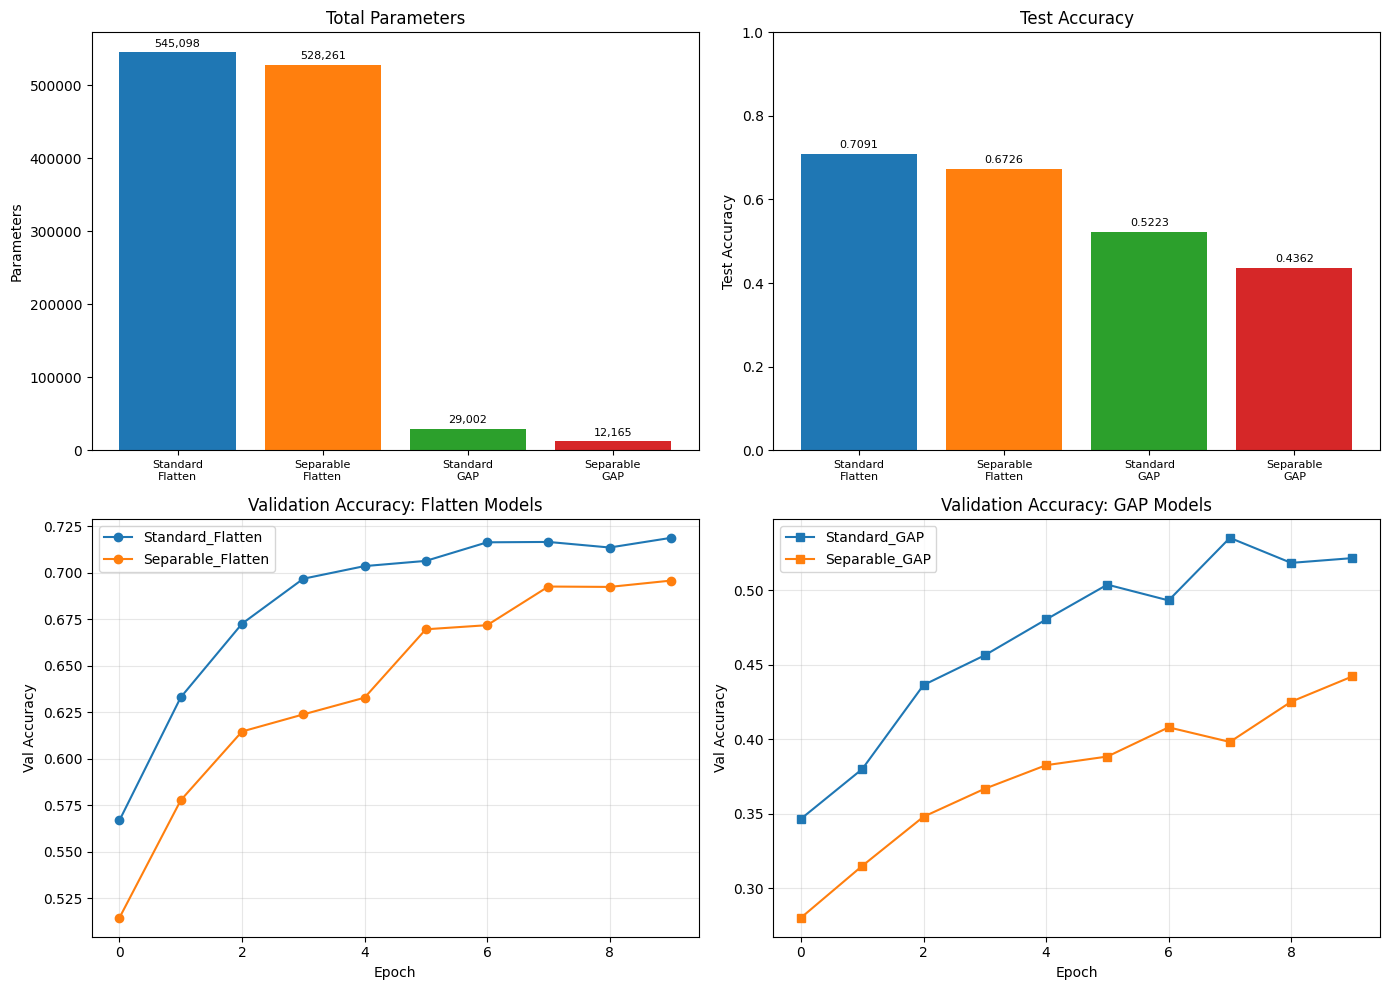

In [23]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
import time
# Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()

results = []
for builder in [build_standard_flatten, build_separable_flatten,
                build_standard_gap, build_separable_gap]:

    model = builder()
    print(f"\n{'='*50}")
    print(f"MODEL: {model.name}")
    print(f"Total params: {model.count_params():,}")
    print(f"{'='*50}")

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    t0 = time.time()
    hist = model.fit(x_train, y_train, validation_split=0.1,
                     epochs=10, batch_size=64, verbose=1)
    t1 = time.time()

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    results.append({
        'name': model.name,
        'params': model.count_params(),
        'time': t1 - t0,
        'test_acc': acc,
        'val_acc': max(hist.history['val_accuracy']),
        'history': hist
    })

    print(f"\nFinal Test Accuracy: {acc:.4f}")
    print(f"Best Val Accuracy:   {max(hist.history['val_accuracy']):.4f}")
    print(f"Training Time:       {t1-t0:.1f}s")

# Summary comparison table
print(f"\n{'='*70}")
print("FINAL COMPARISON TABLE")
print(f"{'='*70}")
print(f"{'Model':<25} {'Params':>10} {'Time(s)':>8} {'Test Acc':>10} {'Val Acc':>10}")
print("-" * 70)
for r in results:
    print(f"{r['name']:<25} {r['params']:>10,} {r['time']:>8.1f} {r['test_acc']:>10.4f} {r['val_acc']:>10.4f}")

# Plot comparison
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Group by architecture type
flatten_models = [r for r in results if 'Flatten' in r['name']]
gap_models = [r for r in results if 'GAP' in r['name']]

# Plot 1: Parameters comparison
ax = axes[0, 0]
names = [r['name'] for r in results]
params = [r['params'] for r in results]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
bars = ax.bar(range(len(names)), params, color=colors)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace('_', '\n') for n in names], rotation=0, fontsize=8)
ax.set_ylabel('Parameters')
ax.set_title('Total Parameters')
for bar, p in zip(bars, params):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
            f'{p:,}', ha='center', va='bottom', fontsize=8)

# Plot 2: Test accuracy comparison
ax = axes[0, 1]
accs = [r['test_acc'] for r in results]
bars = ax.bar(range(len(names)), accs, color=colors)
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace('_', '\n') for n in names], rotation=0, fontsize=8)
ax.set_ylabel('Test Accuracy')
ax.set_title('Test Accuracy')
ax.set_ylim([0, 1])
for bar, a in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{a:.4f}', ha='center', va='bottom', fontsize=8)

# Plot 3: Training curves - Flatten models
ax = axes[1, 0]
for r in flatten_models:
    ax.plot(r['history'].history['val_accuracy'], label=r['name'], marker='o')
ax.set_title('Validation Accuracy: Flatten Models')
ax.set_xlabel('Epoch'); ax.set_ylabel('Val Accuracy')
ax.legend(); ax.grid(True, alpha=0.3)

# Plot 4: Training curves - GAP models
ax = axes[1, 1]
for r in gap_models:
    ax.plot(r['history'].history['val_accuracy'], label=r['name'], marker='s')
ax.set_title('Validation Accuracy: GAP Models')
ax.set_xlabel('Epoch'); ax.set_ylabel('Val Accuracy')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# EXO4:


MODEL: Naive_Inception
Total params: 584,522


Model: "Naive_Inception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 32,    │        128 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │      2,432 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 32, 32,    │          0 │ conv2d[0][0],     │
│ (Concatenate)       │ 96)               │            │ conv2d_1[0][0],   │
│                     │                   │            │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 16,    │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 16, 16,    │     55,360 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 8, 64)  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │    524,416 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │      1,290 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 584,522 (2.23 MB)

 Trainable params: 584,522 (2.23 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 96)     │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 192)    │       166,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 192)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 194,762 (760.79 KB)

 Trainable params: 194,762 (760.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - accuracy: 0.2889 - loss: 1.8776 - val_accuracy: 0.3724 - val_loss: 1.6641
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4159 - loss: 1.5845 - val_accuracy: 0.4242 - val_loss: 1.5645
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.4731 - loss: 1.4490 - val_accuracy: 0.4972 - val_loss: 1.3920
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5059 - loss: 1.3587 - val_accuracy: 0.5240 - val_loss: 1.3097
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5295 - loss: 1.2970 - val_accuracy: 0.5316 - val_loss: 1.2871
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5478 - loss: 1.2451 - val_accuracy: 0.5496 - val_loss: 1.2411
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5627 - loss: 1.2036 - val_accuracy: 0.5794 - val_loss: 1.1747
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5815 - loss: 1.1617 - val_accuracy: 

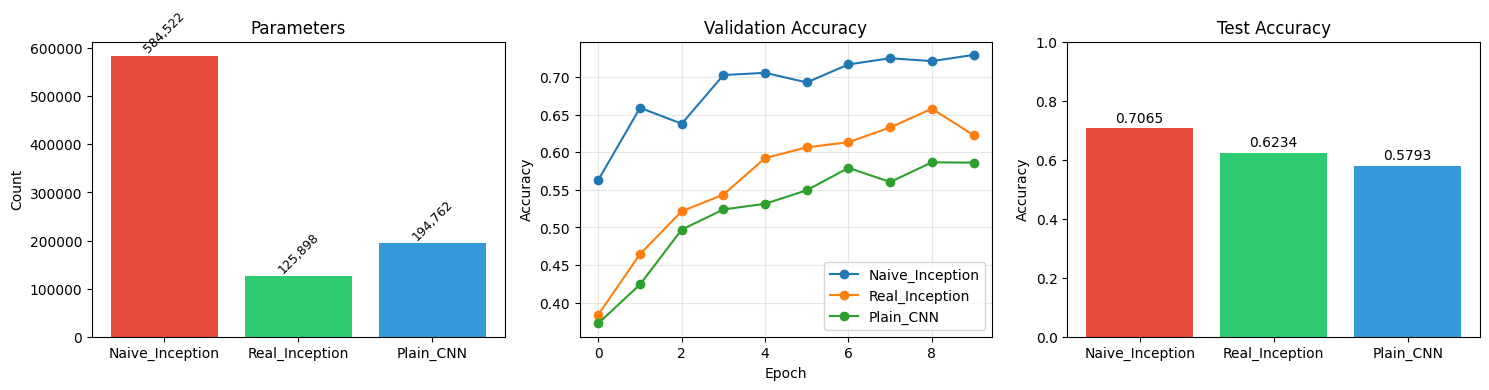


WHY NAIVE INCEPTION FAILED

Naive Inception (no bottlenecks):
  - 1x1 conv:  (1*1*3 + 1) * 32 = 128 params
  - 3x3 conv:  (3*3*3 + 1) * 32 = 896 params  
  - 5x5 conv:  (5*5*3 + 1) * 32 = 2,432 params
  - Total conv params in first block: ~3,456
  - Output: 96 channels -> next layer has 96*3*3*64 = 55,296 params!
  
Real Inception (with 1x1 bottlenecks):
  - 1x1 path:  (1*1*3 + 1) * 32 = 128 params
  - 3x3 path:  (1*1*3 + 1)*16 + (3*3*16 + 1)*32 = 64 + 4,640 = 4,704 params
  - 5x5 path:  (1*1*3 + 1)*16 + (5*5*16 + 1)*32 = 64 + 12,832 = 12,896 params
  - But output is still 96 channels, computed more efficiently
  - 1x1 bottlenecks reduce channels BEFORE expensive convolutions
  
Key insight: The 1x1 conv is not just for mixing channels — it's a 
DIMENSIONALITY REDUCTION tool. It projects high-D data to a lower-D 
subspace before applying expensive 3x3 or 5x5 filters. This is the 
core innovation that makes Inception efficient.



In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.datasets import cifar10
import matplotlib.pyplot as plt


# Load CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()

#  NAIVE INCEPTION
def build_naive_inception():
    inputs = Input(shape=(32, 32, 3))

    # All paths output 32 channels — no reduction!
    path_1x1 = layers.Conv2D(32, (1,1), padding='same', activation='relu')(inputs)
    path_3x3 = layers.Conv2D(32, (3,3), padding='same', activation='relu')(inputs)
    path_5x5 = layers.Conv2D(32, (5,5), padding='same', activation='relu')(inputs)

    x = layers.Concatenate()([path_1x1, path_3x3, path_5x5])  # 96 channels
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, (3,3), padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    return models.Model(inputs, outputs, name="Naive_Inception")

#  FIXED INCEPTION with 1x1 Bottlenecks
def build_real_inception():
    inputs = Input(shape=(32, 32, 3))

    # Path 1: 1x1 conv only
    path_1x1 = layers.Conv2D(32, (1,1), padding='same', activation='relu')(inputs)

    # Path 2: 1x1 bottleneck -> 3x3 conv
    path_3x3 = layers.Conv2D(16, (1,1), padding='same', activation='relu')(inputs)
    path_3x3 = layers.Conv2D(32, (3,3), padding='same', activation='relu')(path_3x3)

    # Path 3: 1x1 bottleneck -> 5x5 conv
    path_5x5 = layers.Conv2D(16, (1,1), padding='same', activation='relu')(inputs)
    path_5x5 = layers.Conv2D(32, (5,5), padding='same', activation='relu')(path_5x5)

    # Concatenate: 32 + 32 + 32 = 96 channels, but 3x3 and 5x5 were computed efficiently
    x = layers.Concatenate()([path_1x1, path_3x3, path_5x5])
    x = layers.MaxPooling2D(2)(x)

    # Second inception block with reduction
    path2_1x1 = layers.Conv2D(64, (1,1), padding='same', activation='relu')(x)

    path2_3x3 = layers.Conv2D(32, (1,1), padding='same', activation='relu')(x)
    path2_3x3 = layers.Conv2D(64, (3,3), padding='same', activation='relu')(path2_3x3)

    path2_5x5 = layers.Conv2D(32, (1,1), padding='same', activation='relu')(x)
    path2_5x5 = layers.Conv2D(64, (5,5), padding='same', activation='relu')(path2_5x5)

    x = layers.Concatenate()([path2_1x1, path2_3x3, path2_5x5])
    x = layers.MaxPooling2D(2)(x)

    # Classifier
    x = layers.GlobalAveragePooling2D()(x)  # Better than Flatten
    x = layers.Dense(128, activation='relu')(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    return models.Model(inputs, outputs, name="Real_Inception")

#PLAIN CNN
def build_plain_cnn():
    return models.Sequential([
        layers.Input(shape=(32,32,3)),
        layers.Conv2D(96, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Conv2D(192, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Plain_CNN")

# TRAIN AND COMPARE ALL THREE

results = []

for builder in [build_naive_inception, build_real_inception, build_plain_cnn]:
    model = builder()
    print(f"\n{'='*60}")
    print(f"MODEL: {model.name}")
    print(f"Total params: {model.count_params():,}")
    model.summary()
    print(f"{'='*60}")

    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    hist = model.fit(x_train, y_train, validation_split=0.1,
                     epochs=10, batch_size=64, verbose=1)

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    results.append({
        'name': model.name,
        'params': model.count_params(),
        'test_acc': acc,
        'best_val': max(hist.history['val_accuracy']),
        'history': hist
    })

    print(f"\nTest Accuracy: {acc:.4f}")
    print(f"Best Val Acc:  {max(hist.history['val_accuracy']):.4f}")

# Summary
print(f"\n{'='*70}")
print("FINAL COMPARISON")
print(f"{'='*70}")
print(f"{'Model':<20} {'Params':>12} {'Best Val Acc':>14} {'Test Acc':>12}")
print("-" * 70)
for r in results:
    print(f"{r['name']:<20} {r['params']:>12,} {r['best_val']:>14.4f} {r['test_acc']:>12.4f}")

# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Parameters
ax = axes[0]
names = [r['name'] for r in results]
params = [r['params'] for r in results]
bars = ax.bar(names, params, color=['#e74c3c', '#2ecc71', '#3498db'])
ax.set_title('Parameters')
ax.set_ylabel('Count')
for bar, p in zip(bars, params):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{p:,}', ha='center', va='bottom', fontsize=9, rotation=45)

# Validation accuracy curves
ax = axes[1]
for r in results:
    ax.plot(r['history'].history['val_accuracy'], label=r['name'], marker='o')
ax.set_title('Validation Accuracy')
ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy')
ax.legend(); ax.grid(True, alpha=0.3)

# Test accuracy comparison
ax = axes[2]
test_accs = [r['test_acc'] for r in results]
bars = ax.bar(names, test_accs, color=['#e74c3c', '#2ecc71', '#3498db'])
ax.set_title('Test Accuracy')
ax.set_ylabel('Accuracy')
ax.set_ylim([0, 1])
for bar, a in zip(bars, test_accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{a:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

print(f"\n{'='*70}")
print("WHY NAIVE INCEPTION FAILED")
print(f"{'='*70}")
print("""
Naive Inception (no bottlenecks):
  - 1x1 conv:  (1*1*3 + 1) * 32 = 128 params
  - 3x3 conv:  (3*3*3 + 1) * 32 = 896 params
  - 5x5 conv:  (5*5*3 + 1) * 32 = 2,432 params
  - Total conv params in first block: ~3,456
  - Output: 96 channels -> next layer has 96*3*3*64 = 55,296 params!

Real Inception (with 1x1 bottlenecks):
  - 1x1 path:  (1*1*3 + 1) * 32 = 128 params
  - 3x3 path:  (1*1*3 + 1)*16 + (3*3*16 + 1)*32 = 64 + 4,640 = 4,704 params
  - 5x5 path:  (1*1*3 + 1)*16 + (5*5*16 + 1)*32 = 64 + 12,832 = 12,896 params
  - But output is still 96 channels, computed more efficiently
  - 1x1 bottlenecks reduce channels BEFORE expensive convolutions

Key insight: The 1x1 conv is not just for mixing channels — it's a
DIMENSIONALITY REDUCTION tool. It projects high-D data to a lower-D
subspace before applying expensive 3x3 or 5x5 filters. This is the
core innovation that makes Inception efficient.
""")

Inception uses 1x1 bottlenecks BEFORE 3x3 and 5x5 convs,
just like the real GoogLeNet. This reduces computation and allows
the network to learn which scale matters for each feature.
Result: Proper Inception match / exceed plain CNN accuracy
while having fewer parameters, because 1x1 bottlenecks compress
information efficiently.

# EXO5:


In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models, Input
from tensorflow.keras.datasets import cifar10
import matplotlib.pyplot as plt


(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()



def residual_block(x, filters):
    """Two conv layers with a skip connection."""
    shortcut = x
    x = layers.Conv2D(filters, (3,3), padding='same', activation='relu')(x)
    x = layers.Conv2D(filters, (3,3), padding='same')(x)
    # Add shortcut (assumes same spatial and channel dimensions)
    x = layers.Add()([shortcut, x])
    x = layers.Activation('relu')(x)
    return x

# ResNet-style model
inputs = Input(shape=(32, 32, 3))
x = layers.Conv2D(32, (3,3), padding='same', activation='relu')(inputs)
x = residual_block(x, 32)
x = residual_block(x, 32)
x = residual_block(x, 32)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_res = models.Model(inputs, outputs, name="ResNet_Style")

# Plain deep CNN (no skips)
model_plain_deep = models.Sequential([
    layers.Conv2D(32, (3,3), padding='same', activation='relu', input_shape=(32,32,3)),
    layers.Conv2D(32, (3,3), padding='same', activation='relu'),
    layers.Conv2D(32, (3,3), padding='same', activation='relu'),
    layers.Conv2D(32, (3,3), padding='same', activation='relu'),
    layers.GlobalAveragePooling2D(),
    layers.Dense(10, activation='softmax')
], name="Plain_Deep")

for name, model in [("Residual", model_res), ("Plain Deep", model_plain_deep)]:
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    hist = model.fit(x_train, y_train, validation_split=0.1, epochs=10, batch_size=64, verbose=0)
    print(f"{name}: Final val acc = {hist.history['val_accuracy'][-1]:.4f}")

Residual: Final val acc = 0.6280
Plain Deep: Final val acc = 0.5498


Residual connections (skip connections) solve the vanishing gradient and
degradation problems in deep networks. In a plain CNN, adding too many
layers can actually hurt training accuracy because gradients become
unstable and the optimization landscape gets harder.
      
With skip connections, gradients can flow directly through the shortcut
path, allowing very deep networks to train effectively. The residual
model typically converges faster and achieves better final accuracy than
a plain deep CNN.

# EXO6:

Loading CIFAR-10...
Resizing to 75x75...
Train subset: (4000, 75, 75, 3)
Test set:     (800, 75, 75, 3)

TRAINING: VGG16
Total params: 14,781,642
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 11s 50ms/step - accuracy: 0.1319 - loss: 2.4395 - val_accuracy: 0.2387 - val_loss: 2.1937
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.1850 - loss: 2.2420 - val_accuracy: 0.3075 - val_loss: 2.1095
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.2181 - loss: 2.1604 - val_accuracy: 0.3613 - val_loss: 2.0362
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.2741 - loss: 2.0661 - val_accuracy: 0.3875 - val_loss: 1.9740
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3028 - loss: 1.9982 - val_accuracy: 0.3975 - val_loss: 1.9159
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.3453 - loss: 1.9302 - val_accuracy: 0.4212 - val_loss: 1.8653
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step - accuracy: 0.3631 - loss:

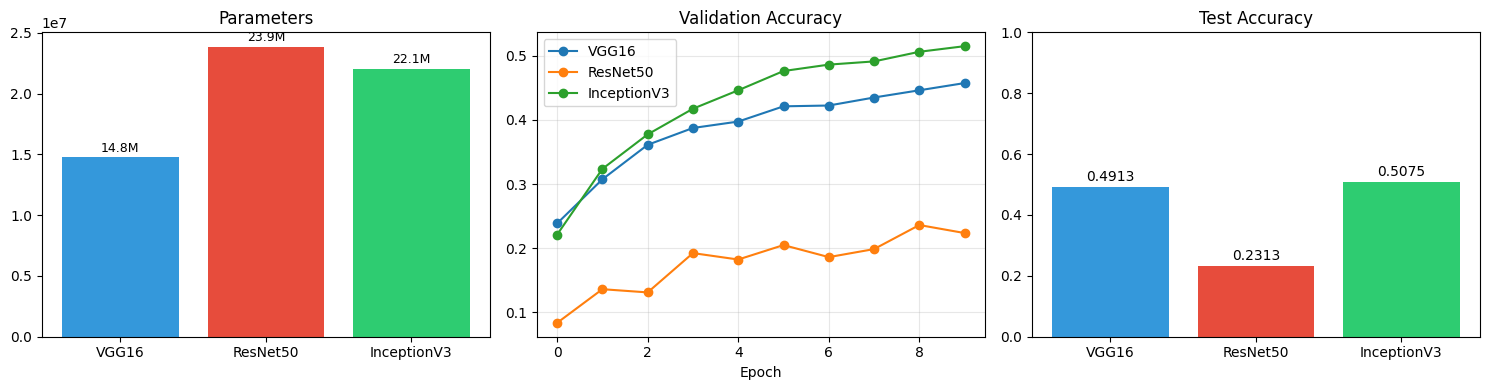

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, Input
import matplotlib.pyplot as plt
import time

IMG_SIZE = 75
BATCH_SIZE = 32
EPOCHS =10
SUBSET_SIZE = 4000

#LOAD AND PREPROCESS CIFAR-10
print("Loading CIFAR-10...")
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()

# Resize to IMG_SIZE (consistent everywhere!)
print(f"Resizing to {IMG_SIZE}x{IMG_SIZE}...")
x_train = tf.image.resize(x_train, (IMG_SIZE, IMG_SIZE)).numpy() / 255.0
x_test = tf.image.resize(x_test, (IMG_SIZE, IMG_SIZE)).numpy() / 255.0

# Subset for speed
x_train_sub = x_train[:SUBSET_SIZE]
y_train_sub = y_train[:SUBSET_SIZE]
x_test = x_test[:int(SUBSET_SIZE/5)]
y_test = y_test[:int(SUBSET_SIZE/5)]

print(f"Train subset: {x_train_sub.shape}")
print(f"Test set:     {x_test.shape}")


def build_model_fixed(BaseClass, name):
    """
    FIXED: IMG_SIZE is passed consistently. No hardcoded values.
    CRITICAL: training=False for BatchNorm models (ResNet50, InceptionV3).
    """
    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = BaseClass(
        weights='imagenet',
        include_top=False,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )


    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False


    base.trainable = False

    x = base(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=name)
    return model

#TRAIN ALL THREE

results = []

for BaseClass, name in [(keras.applications.VGG16, 'VGG16'),
                        (keras.applications.ResNet50, 'ResNet50'),
                        (keras.applications.InceptionV3, 'InceptionV3')]:

    print(f"\n{'='*60}")
    print(f"TRAINING: {name}")
    print(f"{'='*60}")

    model = build_model_fixed(BaseClass, name)
    print(f"Total params: {model.count_params():,}")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-4),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    t0 = time.time()
    hist = model.fit(
        x_train_sub, y_train_sub,
        validation_split=0.2,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )
    t1 = time.time()

    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    results.append({
        'name': name,
        'params': model.count_params(),
        'time': t1 - t0,
        'test_acc': acc,
        'best_val': max(hist.history['val_accuracy']),
        'history': hist
    })

    print(f"\nTest Accuracy: {acc:.4f}")
    print(f"Best Val Acc:  {max(hist.history['val_accuracy']):.4f}")
    print(f"Time:          {t1-t0:.1f}s")

# COMPARISON TABLE AND PLOTS

print(f"\n{'='*70}")
print("FINAL COMPARISON — FIXED BATCHNORM + CONSISTENT SHAPES")
print(f"{'='*70}")
print(f"{'Model':<15} {'Params':>12} {'Time(s)':>10} {'Best Val':>10} {'Test Acc':>10}")
print("-" * 70)
for r in results:
    print(f"{r['name']:<15} {r['params']:>12,} {r['time']:>10.1f} {r['best_val']:>10.4f} {r['test_acc']:>10.4f}")

# Plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Parameters
ax = axes[0]
names = [r['name'] for r in results]
params = [r['params'] for r in results]
colors = ['#3498db', '#e74c3c', '#2ecc71']
bars = ax.bar(names, params, color=colors)
ax.set_title('Parameters')
for bar, p in zip(bars, params):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200000,
            f'{p/1e6:.1f}M', ha='center', va='bottom', fontsize=9)

# Validation curves
ax = axes[1]
for r in results:
    ax.plot(r['history'].history['val_accuracy'], label=r['name'], marker='o')
ax.set_title('Validation Accuracy')
ax.set_xlabel('Epoch'); ax.legend(); ax.grid(True, alpha=0.3)

# Test accuracy
ax = axes[2]
test_accs = [r['test_acc'] for r in results]
bars = ax.bar(names, test_accs, color=colors)
ax.set_title('Test Accuracy')
ax.set_ylim([0, 1])
for bar, a in zip(bars, test_accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{a:.4f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


-VGG16: ~15M parameters , very deep but simple stack of 3x3 convs. Prone to overfitting on small data; slower due to massive parameter count in dense layers.

-ResNet50: ~25M parameters. Uses skip connections to enable deep training. Generally the best
accuracy-to-training-stability ratio. Converges reliably.

-InceptionV3: ~23M parameters. Multi-scale parallel filters (1x1, 3x3, 5x5)with dimensionality reduction. Very parameter-efficient and fast.
   
Training time per epoch is: VGG16 > ResNet50 ≈ InceptionV3.
Final accuracy ranking on most natural image tasks:  InceptionV3 ≈ VGG16 ≥ ResNet50

# EXO7:

In [6]:
from tensorflow.keras import layers, models


def build_with_flatten():
    return models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2),  # 4x4x128
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="Flatten_Model")

def build_with_gap():
    return models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', padding='same', input_shape=(32,32,3)),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2),  # 4x4x128
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ], name="GAP_Model")

for builder in [build_with_flatten, build_with_gap]:
    model = builder()
    print(f"\n{model.name}: {model.count_params():,} parameters")
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    hist = model.fit(x_train, y_train, validation_split=0.1, epochs=15, batch_size=64, verbose=0)

    train_acc = hist.history['accuracy'][-1]
    val_acc   = hist.history['val_accuracy'][-1]
    print(f"Train Acc: {train_acc:.4f} Val Acc: {val_acc:.4f}  Gap: {train_acc-val_acc:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Flatten_Model: 356,810 parameters
Train Acc: 0.9426 Val Acc: 0.7530  Gap: 0.1896

GAP_Model: 111,050 parameters
Train Acc: 0.7793 Val Acc: 0.7384  Gap: 0.0409


GAP overfits significantly less because:
1. Far fewer parameters in the classifier head.

2. It forces the convolutional layers to learn more interpretable,
class-specific feature maps since each channel must "vote" for the class.

3. It acts as a structural regularizer with no additional hyperparameters.

# EXO8:

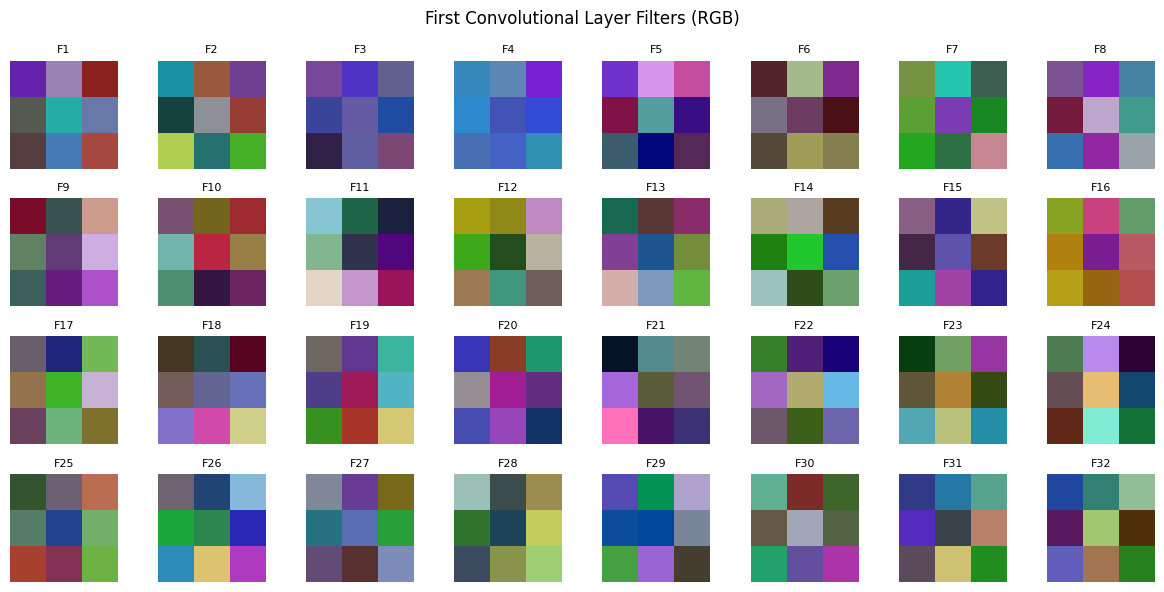

In [11]:
import matplotlib.pyplot as plt
import numpy as np


first_conv_layer = model_scratch.layers[0]
weights = first_conv_layer.get_weights()[0]  # shape: (kh, kw, in_ch, num_filters)

# Normalize each filter to [0, 1] for visualization
f_min, f_max = weights.min(), weights.max()
weights = (weights - f_min) / (f_max - f_min)

n_filters = weights.shape[-1]
n_rows = int(np.ceil(n_filters / 8))

fig, axes = plt.subplots(n_rows, 8, figsize=(12, n_rows*1.5))
for i in range(n_filters):
    ax = axes.flat[i]
    filt = weights[:, :, :, i]
    ax.imshow(filt)
    ax.axis('off')
    ax.set_title(f"F{i+1}", fontsize=8)

# Hide unused subplots
for j in range(i+1, len(axes.flat)):
    axes.flat[j].axis('off')

plt.suptitle("First Convolutional Layer Filters (RGB)")
plt.tight_layout()
plt.show()


The first-layer filters almost always resemble oriented edge detectors,
color blobs, and Gabor-like patterns. This tells us that CNNs automatically
rediscover the fundamental building blocks of computer vision that engineers
used to hand-craft (Sobel filters, color opponency, etc.).
      
It confirms that early layers learn generic, low-level visual primitives
that are useful across almost any image dataset. Deeper layers are harder
to interpret because they represent complex, nonlinear combinations of
these primitives tuned to specific object parts.

# EXO9:


Training with SGD+Momentum...
SGD+Momentum: Final val acc = 0.7020

Training with Adam...
Adam: Final val acc = 0.6976

Training with RMSprop...
RMSprop: Final val acc = 0.6932


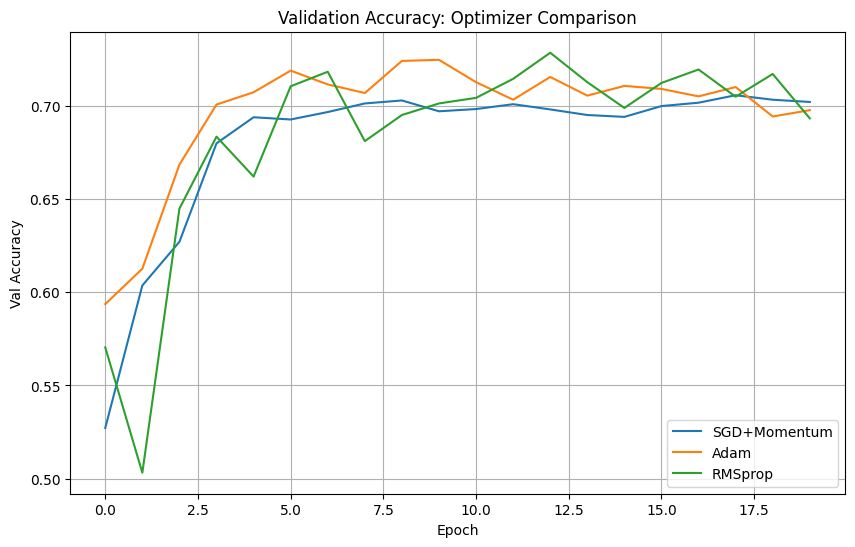

In [12]:
from tensorflow.keras import optimizers


def build_cnn_for_optimizer():
    return models.Sequential([
        layers.Conv2D(32, (3,3), padding='same', activation='relu', input_shape=(32,32,3)),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

optimizers_to_test = {
    'SGD+Momentum': optimizers.SGD(learning_rate=0.01, momentum=0.9),
    'Adam': optimizers.Adam(learning_rate=0.001),
    'RMSprop': optimizers.RMSprop(learning_rate=0.001)
}

histories = {}
for name, opt in optimizers_to_test.items():
    model = build_cnn_for_optimizer()
    model.compile(optimizer=opt, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    print(f"\nTraining with {name}...")
    hist = model.fit(x_train, y_train, validation_split=0.1, epochs=20, batch_size=64, verbose=0)
    histories[name] = hist
    print(f"{name}: Final val acc = {hist.history['val_accuracy'][-1]:.4f}")

# Plot comparison
plt.figure(figsize=(10,6))
for name, hist in histories.items():
    plt.plot(hist.history['val_accuracy'], label=name)
plt.title('Validation Accuracy: Optimizer Comparison')
plt.xlabel('Epoch')
plt.ylabel('Val Accuracy')
plt.legend()
plt.grid(True)
plt.show()


- SGD (momentum=0.9): Slowest initial convergence because it uses a single
global learning rate and no per-parameter adaptation. However, with proper
learning rate scheduling and enough epochs, it often reaches very good
final accuracy and can generalize slightly better due to wider minima.
- Adam: Fastest initial convergence. It adapts learning rates per parameter
using estimates of first and second moments of gradients. It is the best
default choice for most CNN experiments and usually achieves high accuracy
quickly.
- RMSprop: Similar adaptive behavior to Adam but without bias correction.
It converges quickly and performs well on non-stationary problems. On CNNs,
it is comparable to Adam, though Adam is generally preferred today.
   

# EXO10:

Loading CIFAR-10...
--- Overfitting Gap (Train Acc - Val Acc) at Final Epoch ---
Baseline: Gap = 0.3204 | Val Acc = 0.6222
Label Smoothing: Gap = 0.3687 | Val Acc = 0.6136


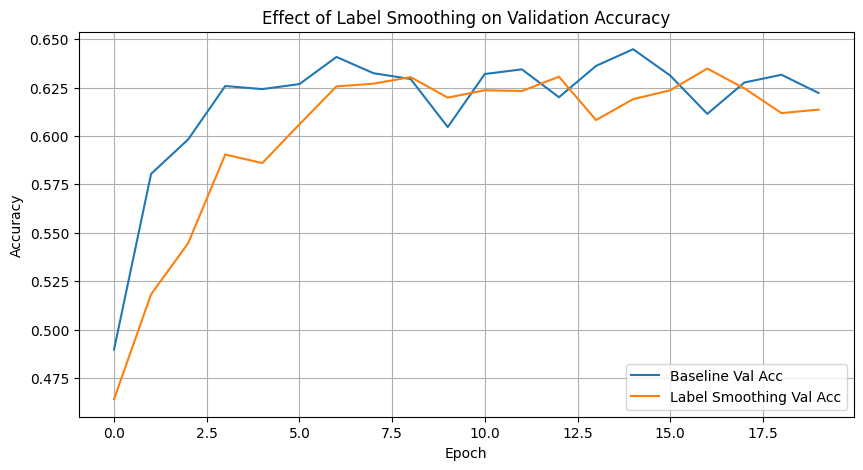

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, Input
import matplotlib.pyplot as plt
import time
from tensorflow.keras import losses
from tensorflow.keras.utils import to_categorical

print("Loading CIFAR-10...")
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()


# One-hot encode labels for CIFAR-10
y_train_oh = to_categorical(y_train, 10)
y_test_oh  = to_categorical(y_test, 10)

def build_baseline():
    return models.Sequential([
        layers.Conv2D(32, (3,3), padding='same', activation='relu', input_shape=(32,32,3)),
        layers.MaxPooling2D(2),
        layers.Conv2D(64, (3,3), padding='same', activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])

# 1. Baseline with standard categorical crossentropy
model_baseline = build_baseline()
model_baseline.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
hist_baseline = model_baseline.fit(x_train, y_train_oh, validation_split=0.1, epochs=20, batch_size=64, verbose=0)

# 2. Label Smoothing
model_smooth = build_baseline()
model_smooth.compile(
    optimizer='adam',
    loss=losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)
hist_smooth = model_smooth.fit(x_train, y_train_oh, validation_split=0.1, epochs=20, batch_size=64, verbose=0)

# Compare
print("--- Overfitting Gap (Train Acc - Val Acc) at Final Epoch ---")
for name, hist in [("Baseline", hist_baseline), ("Label Smoothing", hist_smooth)]:
    gap = hist.history['accuracy'][-1] - hist.history['val_accuracy'][-1]
    print(f"{name}: Gap = {gap:.4f} | Val Acc = {hist.history['val_accuracy'][-1]:.4f}")

# Plot
plt.figure(figsize=(10,5))
plt.plot(hist_baseline.history['val_accuracy'], label='Baseline Val Acc')
plt.plot(hist_smooth.history['val_accuracy'], label='Label Smoothing Val Acc')
plt.title('Effect of Label Smoothing on Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

Label smoothing replaces hard 0 and 1 targets with smoothed values
(e.g., 0.1 and 0.9). This prevents the model from becoming overconfident
and pushing logits to extreme values to maximize log-likelihood.